In [1]:
#library(locfit)

In [2]:
Output = ('/Users/alexis/Library/CloudStorage/OneDrive-UniversityofNorthCarolinaatChapelHill/CEMALB_DataAnalysisPM/Projects/P1016. THC Adducts/P1016.3. Analyses/P1016.3.1. Data Normalization/Output')
cur_date = "110726"

library(readxl)
library(openxlsx)
library(tidyverse)
library(reshape2)
library(data.table)
library(factoextra)
library(ggrepel)
library(pheatmap)
library(DESeq2)

# reading in files
countdata = data.frame(read_excel("Input/THC_Adducts_091426.xlsx", sheet = 3)) 
sample_df = data.frame(read_excel("Input/D8_D8Q_12_coldata.xlsx"))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘reshape2’


The following object is masked from ‘package:tidyr’:

    smiths



Attaching package: ‘data.table’


The following objects are masked from ‘package:reshape2’:

    dcast, melt


The following objects are masked from ‘package:lubridate’:

    hour, isoweek, mday, minute, month, quarter, second, wday, week,
    yday, year


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is masked from

In [3]:
head(countdata)
head(sample_df)

,ENSEMBL_ID,P1_Control,P2_Control,P3_Control,P1_D8THC,P2_D8THC,P3_D8THC,P1_D8THCq,P2_D8THCq,P3_D8THCq
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,ENSG00000223972,0,0,0,0,0,1,0,0,0
2,ENSG00000227232,137,107,140,119,153,112,47,137,10
3,ENSG00000278267,3,1,11,14,2,7,0,6,1
4,ENSG00000243485,3,0,0,2,0,1,0,0,0
5,ENSG00000237613,0,0,0,0,0,0,0,0,0
6,ENSG00000268020,0,0,0,0,0,0,0,0,0


,Sample_ID,Exposure
,<chr>,<chr>
1,P1_Control,Control
2,P2_Control,Control
3,P3_Control,Control
4,P1_D8THC,D8THC
5,P2_D8THC,D8THC
6,P3_D8THC,D8THC


In [4]:
# reformatting for the deseq2 function
countdata = countdata %>%
    column_to_rownames(var = "ENSEMBL_ID")
head(countdata)

,P1_Control,P2_Control,P3_Control,P1_D8THC,P2_D8THC,P3_D8THC,P1_D8THCq,P2_D8THCq,P3_D8THCq
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000223972,0,0,0,0,0,1,0,0,0
ENSG00000227232,137,107,140,119,153,112,47,137,10
ENSG00000278267,3,1,11,14,2,7,0,6,1
ENSG00000243485,3,0,0,2,0,1,0,0,0
ENSG00000237613,0,0,0,0,0,0,0,0,0
ENSG00000268020,0,0,0,0,0,0,0,0,0


In [5]:
# creating a df that has a column for the "exposure"
coldata = sample_df %>%
    separate(Sample_ID, sep = "_", c("Experiment", NA), remove = FALSE)
# coldata = count_df %>%
#     pivot_longer(cols = 2:10, names_to = "Sample_ID", values_to = "Value") %>%
#     separate(Sample_ID, sep = "_", c("Experiment", "Exposure"), remove = FALSE) %>%
#     select(-c('ENSEMBL_ID', 'Value')) %>%
#     unique()

head(coldata)

,Sample_ID,Experiment,Exposure
,<chr>,<chr>,<chr>
1,P1_Control,P1,Control
2,P2_Control,P2,Control
3,P3_Control,P3,Control
4,P1_D8THC,P1,D8THC
5,P2_D8THC,P2,D8THC
6,P3_D8THC,P3,D8THC


In [6]:
# Double checking that the same variables appear between the two dataframes
setequal(as.character(coldata$Sample_ID), colnames(countdata))

# Additionally checking that not only the sets of variables are the same, but that they are in the same order
identical(as.character(coldata$Sample_ID), colnames(countdata))

[1] TRUE

[1] TRUE

In [7]:
nrow(countdata)

[1] 57500

# Transcriptomics QA/QC

Performed on raw count data to identify potential outlier samples. Starting by filtering lowly expressed genes.

In [8]:
# First count the total number of samples and save it as a value in the global environment
nsamp <- ncol(countdata)

# Then, calculate the median expression level across all genes and all samples and save it as a value
total_median <- median(as.matrix(countdata), na.rm = TRUE)

# We need to temporarily add back in the gene column to the countdata 
# so we can filter for genes that pass the background filter
countdata <- countdata %>% 
    rownames_to_column("Gene")

head(countdata)

,Gene,P1_Control,P2_Control,P3_Control,P1_D8THC,P2_D8THC,P3_D8THC,P1_D8THCq,P2_D8THCq,P3_D8THCq
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,ENSG00000223972,0,0,0,0,0,1,0,0,0
2,ENSG00000227232,137,107,140,119,153,112,47,137,10
3,ENSG00000278267,3,1,11,14,2,7,0,6,1
4,ENSG00000243485,3,0,0,2,0,1,0,0,0
5,ENSG00000237613,0,0,0,0,0,0,0,0,0
6,ENSG00000268020,0,0,0,0,0,0,0,0,0


In [9]:
# filtering for genes that have an expression greater than the total median in at least 20% of the samples
genes_above_background <- countdata %>% 
    pivot_longer(cols =! Gene, names_to = "SampleID", values_to = "expression") %>% 
    # indicates whether the expression of a gene for the corresponding exposure condition is above (1) or not 
    # above (0) the median of all count data
    mutate(above_median = ifelse(expression > total_median, 1, 0)) %>% 
    group_by(Gene) %>% 
    # For each gene, count the number of exposure conditions where the expression was greater than the median 
    # of all count data
    summarize(total_above_median = sum(above_median)) %>% 
    # Filter for genes that have expression above the median in at least 20% of the samples
    filter(total_above_median >= 0.2 * nsamp) %>% 
    select(Gene) 

# Then filter the original 'countdata' dataframe for only the genes above background. 
countdata <- left_join(genes_above_background, countdata, by = "Gene")

dim(countdata)

[1] 28893    10

This dataframe went from having 57,500 genes to 28,893 genes. Now filtering samples with no expression.

In [10]:
countdata_T <- countdata %>% 
  pivot_longer(cols =! Gene, names_to = "Sample_ID",values_to = "expression") %>% 
  pivot_wider(names_from = Gene, values_from = expression)

# Then add in a column to the transposed countdata dataframe that sums expression across all genes for each 
# exposure condition
countdata_T$rowsum <- rowSums(countdata_T[2:ncol(countdata_T)])

# Remove samples that have no expression
countdata_T <- countdata_T %>% 
    filter(rowsum != 0)

# Take the count data filtered for correct samples, remove the 'rowsums' column
countdata_T <- countdata_T %>% 
    select(!rowsum) 

# Then, transpose it back to the correct format for analysis
countdata <- countdata_T %>%
  pivot_longer(cols =! Sample_ID, names_to = "Gene", values_to = "expression") %>% 
  pivot_wider(names_from = Sample_ID, values_from = "expression") %>%
    column_to_rownames(var = "Gene")

dim(countdata)

[1] 28893     9

No samples were removed. Now finding and removing sample outliers using PCA and hierarchical clustering.

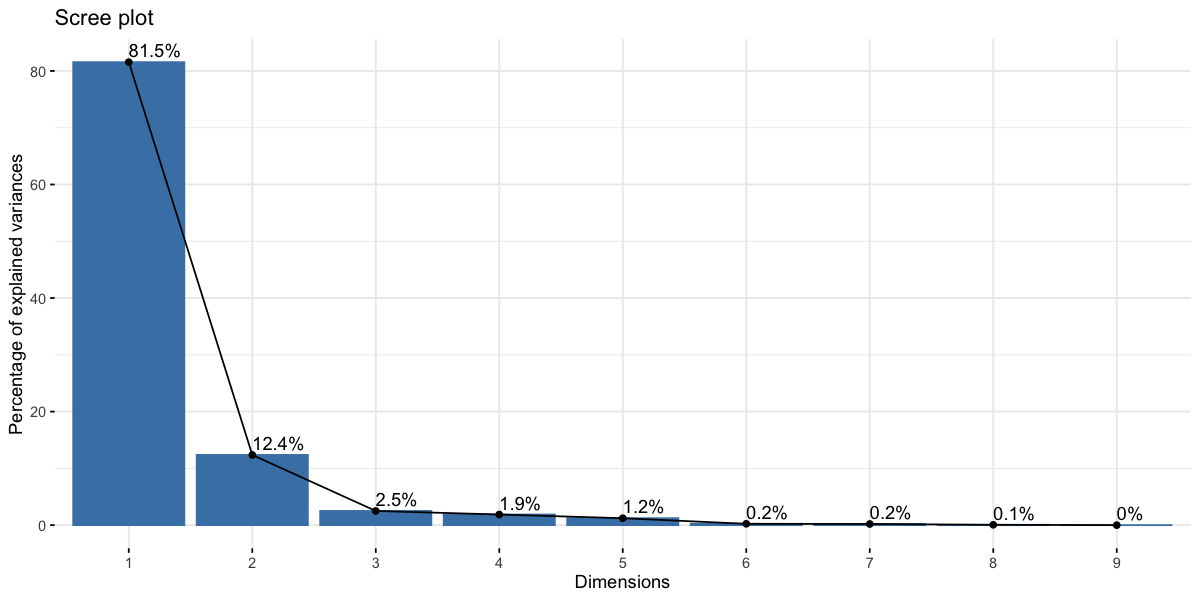

In [11]:
# PCA helps in identifying outlying samples for quality control and gives a feeling for the principal causes of 
# variation in a dataset

# Calculate principal components using transposed count data
pca <- prcomp(t(countdata))

options(repr.plot.width = 10, repr.plot.height = 5) #changing size
fviz_eig(pca, addlabels = TRUE)

In [12]:
# Make dataframe for PCA plot generation using first two components and the sample name
pca_df <- data.frame(PC1 = pca$x[,1], PC2 = pca$x[,2], Sample_ID = colnames(countdata))

# Calculating percent of the variation that is captured by each principal component
pca_percent <- round(100 * pca$sdev^2/sum(pca$sdev^2), 1)

# Organize dataframe so we can color our points by burn condition
# pca_df <- pca_df %>% 
#     inner_join(coldata)

head(pca_df)

,PC1,PC2,Sample_ID
,<dbl>,<dbl>,<chr>
P1_Control,-87723.55,33208.724,P1_Control
P2_Control,-87645.07,-67535.067,P2_Control
P3_Control,-70505.69,2478.568,P3_Control
P1_D8THC,-80636.85,39992.418,P1_D8THC
P2_D8THC,-91683.72,7789.444,P2_D8THC
P3_D8THC,-70958.14,50036.803,P3_D8THC


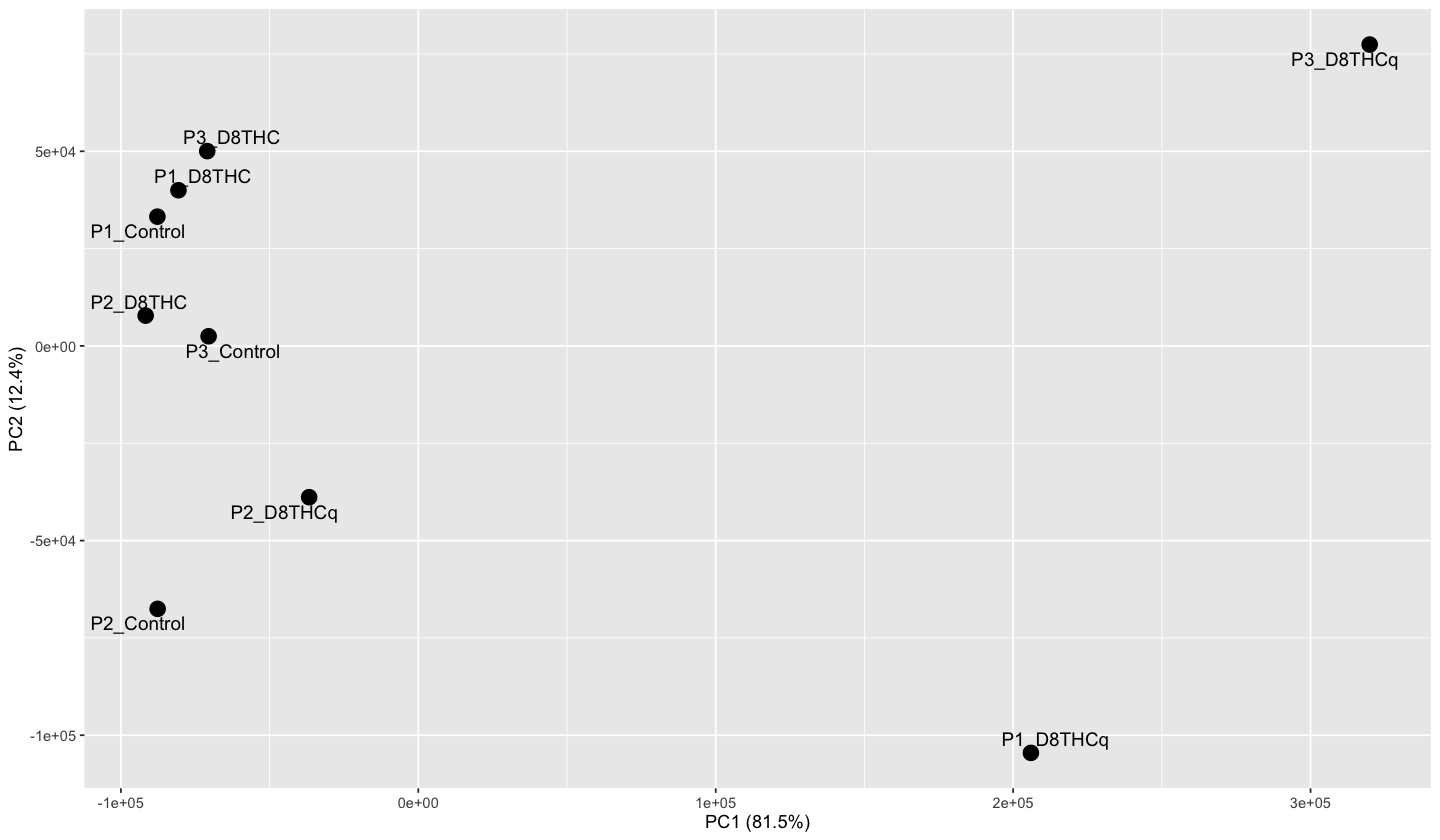

In [13]:
options(repr.plot.width=12, repr.plot.height=7) #changing size

# color by sex since that's a covariate we're interested in
ggplot(pca_df, aes(PC1, PC2)) +
  geom_point(size = 4) +
  geom_text_repel(aes(label = Sample_ID), size = 4) +
  labs(x = paste0("PC1 (",pca_percent[1],"%)"), y = paste0("PC2 (",pca_percent[2],"%)"))

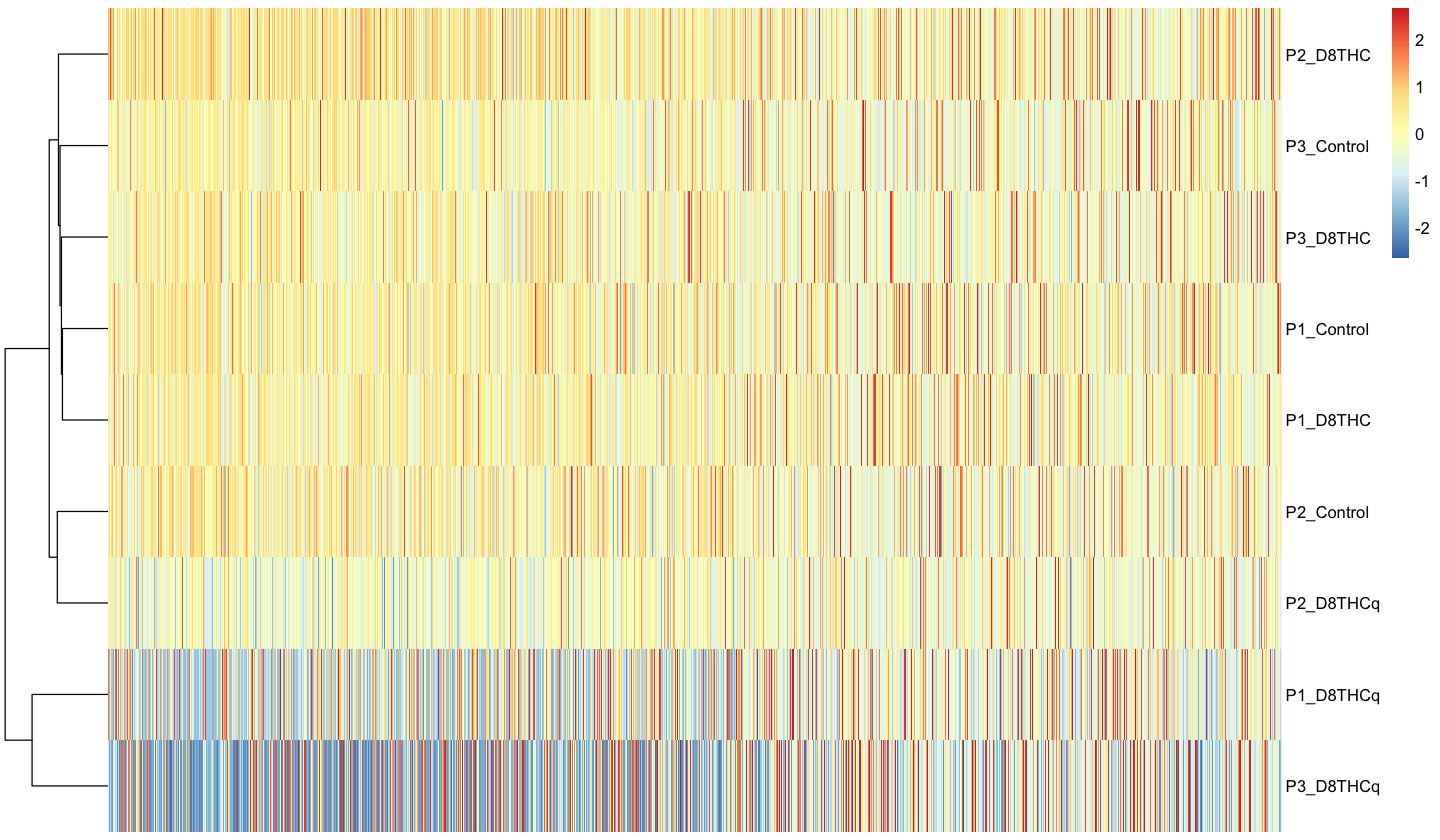

In [14]:
countdata_for_clustering <- t(countdata)

pheatmap(scale(countdata_for_clustering), 
         cluster_rows = TRUE, cluster_cols = FALSE, fontsize_col = 7, treeheight_row = 60, show_colnames = FALSE)

There might be two outliers from PCA or hierarchical clustering, so now we'll use a quantitative approach. The standard way to detect outliers in genetics is the criterion of being “more than 6 standard deviations away from the mean”. [source](https://privefl.github.io/blog/detecting-outlier-samples-in-pca/)

In [15]:
outlier_detection = function(pca_df){
    # """
    # Creating a scoring function for to detect PCA sample outliers. 
    # :param (input): PCA df (df)
    # :output: outlier names
    # """
    
    # getting scores
    scores = pca_df$x
    # identifying samples that are > 6 standard deviations away from the mean
    outlier_indices = apply(scores, 2, function(x) which( abs(x - mean(x)) > (6 * sd(x)) )) %>%
        Reduce(union, .)
    # getting sample names
    outliers = rownames(scores)[outlier_indices]
    
    return(outliers)
}

# calling fn
gene_outliers = outlier_detection(pca)  

In [16]:
# getting length
length(gene_outliers)

[1] 0

There were no sample or gene outliers.

# DESeq2 Experiment

In [17]:
# Starting with putting variables into factors
coldata$Exposure = factor(coldata$Exposure)
levels(coldata$Exposure)

[1] "Control" "D8THC"   "D8THCQ"

In [18]:
head(countdata)
head(coldata)

,P1_Control,P2_Control,P3_Control,P1_D8THC,P2_D8THC,P3_D8THC,P1_D8THCq,P2_D8THCq,P3_D8THCq
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000000003,2383,2228,2238,2259,2464,2179,1715,2007,1289
ENSG00000000419,1910,1730,1861,1914,1911,2032,1961,1677,1373
ENSG00000000457,277,291,234,268,315,299,127,204,165
ENSG00000000460,994,856,912,958,1076,1016,154,605,62
ENSG00000000938,16,6,1,0,32,19,41,5,0
ENSG00000000971,12,5,10,5,14,12,47,23,75


,Sample_ID,Experiment,Exposure
,<chr>,<chr>,<fct>
1,P1_Control,P1,Control
2,P2_Control,P2,Control
3,P3_Control,P3,Control
4,P1_D8THC,P1,D8THC
5,P2_D8THC,P2,D8THC
6,P3_D8THC,P3,D8THC


We're interested in comparing gene expression changes after exposure to THC, but we're more interested in getting the normalized counts.

In [19]:
# Our design indicates that our count data is dependent on the exposure condition 
# (Exposure variable) and our factor of unwanted variation, and we can specify 
# that there not be an intercept term through the use of '~0'

# crude model
dds <- DESeqDataSetFromMatrix(countData = countdata, colData = coldata, design = ~Exposure)

# View what the experiment contains
dds

converting counts to integer mode



class: DESeqDataSet 
dim: 28893 9 
metadata(1): version
assays(1): counts
rownames(28893): ENSG00000000003 ENSG00000000419 ... ENSG00000283696
  ENSG00000283697
rowData names(0):
colnames(9): P1_Control P2_Control ... P2_D8THCq P3_D8THCq
colData names(3): Sample_ID Experiment Exposure

In [20]:
# estimate the size factors, since size factors are used to normalize the counts (next step)
# The "iterate" estimator iterates between estimating the dispersion with a design of ~1, and finding a size factor vector by numerically 
# optimizing the likelihood of the ~1 model.
dds <- estimateSizeFactors(dds)

sizeFactors(dds) 

P1_Control P2_Control P3_Control   P1_D8THC   P2_D8THC   P3_D8THC  P1_D8THCq 
 1.1721313  1.1695365  1.1495723  1.1584270  1.2501875  1.1282207  0.7871921 
 P2_D8THCq  P3_D8THCq 
 1.0019292  0.5437621

In [21]:
# normalized counts
normcounts <- counts(dds, normalized = TRUE)

# log2 pseudocounts
log2normcounts <- log2(normcounts + 1)

In [22]:
# Background filter: remove rows with only zeros or only a single count across all samples
idx <- rowSums(normcounts) > 1     
CountsAboveBack <- normcounts[idx,]
nrow(CountsAboveBack)
    
# Also need to filter in the entire DESeq2 experiment
dds <- dds[rowSums(counts(dds, normalized = TRUE)) > 1, ]

[1] 28893

No genes were removed.

## Statistical Analysis to detect Differentially Expressed Genes

In [23]:
# Running the differential expression statistical pipeline
# because we used a user-defined model matrix, need to set betaPrior = FALSE
dds <- DESeq(dds, betaPrior = FALSE) 

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [24]:
# creating a df of contrasts for the function to loop through
contrasts_df = data.frame(Treatment = c("D8THC", "D8THCQ", "D8THCQ"), Control = c("Control", "Control", "D8THC"))
head(contrasts_df)

,Treatment,Control
,<chr>,<chr>
1,D8THC,Control
2,D8THCQ,Control
3,D8THCQ,D8THC


In [25]:
 significant_genes_df = data.frame()
    for (i in 1:length(contrasts_df$Treatment)){
    
        # Pulling statistical results
        #Statistical output with multiple test correction by the default, BH (aka FDR)
        res <- results(dds, pAdjustMethod = "BH", contrast = c("Exposure", contrasts_df$Treatment[i], 
                                                                          contrasts_df$Control[i]))
        
        # Exporting statistical results
        res_df = data.frame(res)[order(res$padj),] 
        filtered_res_df = res_df %>% 
            # adding exposure comparisons
            mutate(Treatment = contrasts_df$Treatment[i], Control = contrasts_df$Control[i]) %>%
            rownames_to_column(var = "Gene")

        # saving results
        significant_genes_df = rbind(significant_genes_df, filtered_res_df)
        
      }

significant_genes_df = significant_genes_df[,c(1,3,6:9)]
colnames(significant_genes_df)[2:4] = c('log2FC', 'P Value', 'P Adj')
head(significant_genes_df)

,Gene,log2FC,P Value,P Adj,Treatment,Control
,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
1,ENSG00000000003,-0.007988413,0.9461493,1,D8THC,Control
2,ENSG00000000419,0.075514481,0.6994330,1,D8THC,Control
3,ENSG00000000457,0.119709242,0.6461443,1,D8THC,Control
4,ENSG00000000460,0.125056396,0.7907686,1,D8THC,Control
5,ENSG00000000938,1.111036342,0.4973247,1,D8THC,Control
6,ENSG00000000971,0.173825486,0.8245174,1,D8THC,Control


In [26]:
# total significant gene counts
sig_genes_count_df = significant_genes_df %>%
    # filtering for only sig genes
    filter(`P Adj` < 0.05 & log2FC > log2(1.5) | `P Adj` < 0.05 & log2FC < -log2(1.5)) %>%
    select(Gene) %>%
    distinct() %>%
    summarize(n())

sig_genes_count_df

n()
<int>
6879


In [27]:
# saving the normalized counts too 
norm_df = data.frame(normcounts) %>% 
    rownames_to_column("ENSEMBL_ID")

log2_norm_df = data.frame(log2normcounts) %>% 
    rownames_to_column("ENSEMBL_ID")

head(norm_df)

,ENSEMBL_ID,P1_Control,P2_Control,P3_Control,P1_D8THC,P2_D8THC,P3_D8THC,P1_D8THCq,P2_D8THCq,P3_D8THCq
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,ENSG00000000003,2033.04861,1905.028178,1946.8109323,1950.058086,1970.90437,1931.35964,2178.62954,2003.135529,2370.5221
2,ENSG00000000419,1629.51022,1479.218468,1618.8628887,1652.240450,1528.57072,1801.06599,2491.13267,1673.770943,2525.0015
3,ENSG00000000457,236.32164,248.816517,203.5539581,231.348193,251.96221,265.01906,161.33292,203.607199,303.4415
4,ENSG00000000460,848.02783,731.913878,793.3385032,826.983465,860.67090,900.53299,195.63204,603.835075,114.0205
5,ENSG00000000938,13.65035,5.130237,0.8698887,0.000000,25.59616,16.84068,52.08385,4.990373,0.0000
6,ENSG00000000971,10.23776,4.275198,8.6988871,4.316198,11.19832,10.63622,59.70588,22.955714,137.9280


In [29]:
# exporting
write.xlsx(norm_df, paste0(Output,"/", "Normalized_THC_Genes_", cur_date, ".xlsx"), 
           rowNames = FALSE)
write.xlsx(log2_norm_df, paste0(Output,"/", "log2_Normalized_THC_Genes_", cur_date, ".xlsx"), 
           rowNames = FALSE)
write.xlsx(significant_genes_df, paste0(Output,"/", "DESeq2_Results_", cur_date, ".xlsx"), 
           rowNames = FALSE)